In [1]:
# import respective libraries
import pandas as pd
import numpy as np

# Setting random seed for reproducibility
np.random.seed(42)

# Parameters for the data
n_records = 50000
truck_ids = [f"TRK-{str(i).zfill(3)}" for i in range(1, 101)] # 100 trucks
routes = ["Durban -> Johannesburg (N3)", "Cato Ridge -> Harrismith", "Pietermaritzburg -> Johannesburg"]
drivers = ["S. Dlamini", "J. van der Merwe", "T. Khumalo", "M. Botha", "K. Naidoo", "B. Mokoena"]

print("Generating base N3 corridor fleet telemetry...")

# 1.Generate base dataframe
data = {
    "Trip_ID": [f"TRIP-{10000 + i}" for i in range(n_records)],
    "Truck_ID": np.random.choice(truck_ids, n_records),
    "Driver_Name": np.random.choice(drivers, n_records),
    "Route_Leg": np.random.choice(routes, n_records),
    "Expected_Fuel_Liters": np.random.uniform(80, 150, n_records).round(2),
    "Idle_Time_Mins": np.random.normal(25, 8, n_records).clip(5, 60).round(1)
}

df = pd.DataFrame(data)

# Calculate baseline actual fuel close to expected
df["Actual_Fuel_Liters"] = df["Expected_Fuel_Liters"] * np.random.normal(1.0, 0.03, n_records)

# 2.THE TROJAN HORSE: Injecting Intentional Financial Anomalies
# Force 5 specific rogue trucks to consistently burn 18% to 25% more fuel than expected
rogue_trucks = ["TRK-012", "TRK-045", "TRK-078", "TRK-089", "TRK-033"]
rogue_mask = df["Truck_ID"].isin(rogue_trucks)

# Inject fuel variance anomaly
df.loc[rogue_mask, "Actual_Fuel_Liters"] = df.loc[rogue_mask, "Expected_Fuel_Liters"] * np.random.uniform(1.18, 1.25, rogue_mask.sum())

# Inject severe idle time anomalies at specific loading hubs
df.loc[df["Route_Leg"] == "Cato Ridge -> Harrismith", "Idle_Time_Mins"] += np.random.uniform(30, 75, (df["Route_Leg"] == "Cato Ridge -> Harrismith").sum())

# Round final fuel numbers
df["Actual_Fuel_Liters"] = df["Actual_Fuel_Liters"].round(2)
df["Variance_Percent"] = (((df["Actual_Fuel_Liters"] - df["Expected_Fuel_Liters"]) / df["Expected_Fuel_Liters"]) * 100).round(2)

# 3.Export to CSV
output_file = "n3_fleet_anomalies_50k.csv"
df.to_csv(output_file, index=False)

print(f"Success! Generated {n_records} records with embedded anomalies.")
print(f"Saved to {output_file}")

Generating base N3 corridor fleet telemetry...
Success! Generated 50000 records with embedded anomalies.
Saved to n3_fleet_anomalies_50k.csv


In [15]:
import pandas as pd

# Loading synthetic dataset
df = pd.read_csv("n3_fleet_anomalies_50k.csv")

# Quick look at the top rows
df.head()

# Filtering for those 5 rogue trucks to see how much extra fuel they burned
rogue_trucks = ["TRK-012", "TRK-045", "TRK-078", "TRK-089", "TRK-033"]
rogue_summary = df[df["Truck_ID"].isin(rogue_trucks)].groupby("Truck_ID")["Variance_Percent"].mean().reset_index()

print(rogue_summary)

  Truck_ID  Variance_Percent
0  TRK-012         21.666140
1  TRK-033         21.422332
2  TRK-045         21.504149
3  TRK-078         21.468098
4  TRK-089         21.488269


                      Dataset Summary Statistics


,Expected_Fuel_Liters,Actual_Fuel_Liters,Idle_Time_Mins,Variance_Percent
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,115.086657,116.305797,42.400833,1.059758
std,20.222185,21.432177,27.050355,5.520075
min,80.000000,73.940000,5.000000,-13.410000
25%,97.500000,98.297500,22.400000,-1.900000
50%,115.150000,116.000000,30.300000,0.200000
75%,132.600000,133.620000,65.654755,2.410000
max,150.000000,187.360000,126.458111,25.000000


C:\Users\lindo\AppData\Local\Temp\ipykernel_21392\718649100.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Route_Leg", y="Variance_Percent", data=df, palette="Set2")


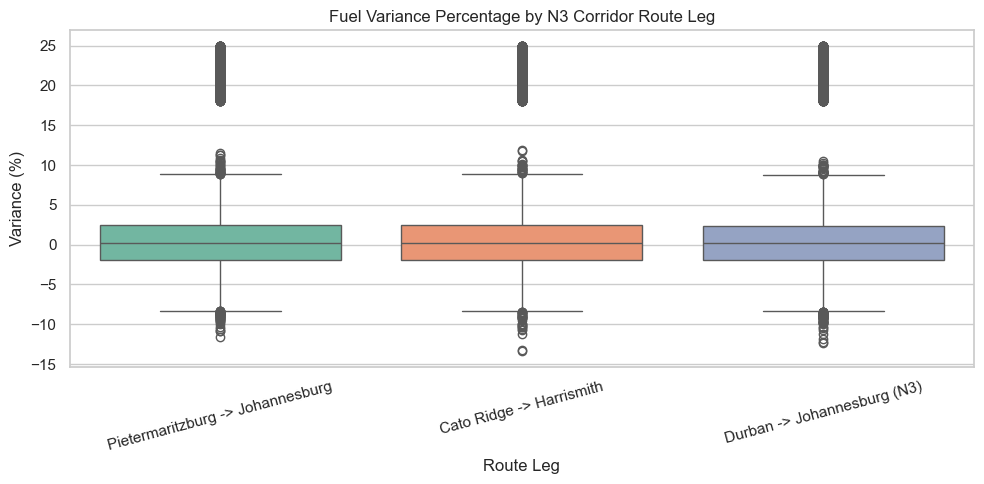

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("n3_fleet_anomalies_50k.csv")

# 1.Descriptive Statistics Overview
print("                      Dataset Summary Statistics")
display(df[["Expected_Fuel_Liters", "Actual_Fuel_Liters", "Idle_Time_Mins", "Variance_Percent"]].describe())

# 2.Visualization: Fuel Variance Distribution across Route Legs
plt.figure(figsize=(10, 5))
sns.boxplot(x="Route_Leg", y="Variance_Percent", data=df, palette="Set2")
plt.title("Fuel Variance Percentage by N3 Corridor Route Leg")
plt.xlabel("Route Leg")
plt.ylabel("Variance (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

# Define target: Is the trip an anomaly? (1 if Variance > 10%, else 0)
df["Is_Anomaly"] = (df["Variance_Percent"] > 10).astype(int)

# Select features and target
x = df[["Expected_Fuel_Liters", "Idle_Time_Mins"]]
y = df["Is_Anomaly"]

# Train/Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# Initialize and train Random Forest model
rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(x_train, y_train)

# Evaluate
y_pred = rf_model.predict(x_test)
print(f"Model Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 94.41%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      9484
           1       0.04      0.00      0.01       516

    accuracy                           0.94     10000
   macro avg       0.50      0.50      0.49     10000
weighted avg       0.90      0.94      0.92     10000

